# ¿Cuánta energía cuesta romper una contraseña por fuerza bruta?

**Física A: Hardware e Información — Proyecto final**
Profesor: Andrés Flórez

**Integrantes:** Felipe Rojas Díaz · Alejandra Rodríguez · Samuel Fonseca

> **Pregunta.** ¿Cuánto tiempo y energía cuesta romper una contraseña de $N$ caracteres con una GPU que se calienta y reduce su frecuencia (*throttling*), cuánto cambia eso con la calidad de la refrigeración, y desde qué longitud la termodinámica hace imposible el ataque?

## 1. Introducción

Un ataque de fuerza bruta prueba todas las combinaciones posibles de una contraseña. Con un alfabeto de 95 caracteres imprimibles, una contraseña de $N$ caracteres tiene $95^N$ combinaciones. Una GPU moderna prueba cientos de miles de millones por segundo, pero cada intento es trabajo eléctrico que termina como **calor** en el chip. El chip se calienta, se protege bajando su frecuencia y el ataque se vuelve más lento y más caro.

En este notebook construimos ese modelo paso a paso: primero la dinámica térmica del chip, después el frenado, luego el costo del ataque y, al final, el límite fundamental que impone la termodinámica (principio de Landauer).

## 2. Modelo físico

### 2.1 Balance de energía del chip

Tratamos el chip y su disipador como **un solo cuerpo** a temperatura uniforme $T$, con capacidad térmica $C_{th} = m\,c$. Por la primera ley, la energía que entra (potencia eléctrica $P$) menos la que sale al ambiente por conducción cambia su temperatura:

$$
C_{th}\,\frac{dT}{dt} \;=\; P \;-\; \frac{T - T_{amb}}{R_{th}}
$$

- $P$: potencia eléctrica disipada por el chip (W). Toda termina como calor.
- $R_{th} = \dfrac{L}{kA}$: resistencia térmica entre el chip y el aire (K/W). Un buen disipador y buena pasta térmica dan un $R_{th}$ pequeño.
- $T_{amb}$: temperatura del ambiente.

Es exactamente la misma ecuación que la de un **circuito RC**: $C_{th}$ hace el papel del condensador, $R_{th}$ el de la resistencia y $P$ el de una fuente de corriente. Por eso aparece una constante de tiempo

$$
\tau = R_{th}\,C_{th}.
$$

### 2.2 Potencia y velocidad del ataque *(se usa desde la Fase 2)*

La potencia dinámica de un chip CMOS es $P \approx C\,V^2 f$ (cargar y descargar condensadores en cada ciclo de reloj), y la velocidad de intentos es proporcional a la frecuencia: $r \propto f$.

### 2.3 Frenado térmico *(Fase 2)*

Si $T$ supera un límite $T_{lím} \approx 83\ ^\circ\mathrm{C}$, el chip reduce $f$. Esa realimentación vuelve el sistema **no lineal**.

### 2.4 Refrigeración y límite de Landauer *(Fase 4)*

Sacar el calor $Q$ de un cuarto cuesta un trabajo $W = Q/\mathrm{COP}$ (cota de Carnot). Y por debajo de toda la tecnología, cada operación lógica irreversible cuesta al menos $k_B T \ln 2$.

### 2.5 Suposiciones

1. Temperatura uniforme en el chip y el disipador (un solo nodo térmico).
2. Temperatura ambiente constante.
3. La potencia depende solo de la frecuencia de reloj.
4. Computación irreversible (para aplicar Landauer).

## 3. Parámetros

Todos los parámetros están en una sola celda, con unidades y origen. Los valores térmicos son **estimaciones iniciales**; los ajustaremos con nuestra medición propia (Fase 3).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo de las gráficas (colores fijos por serie, rejilla suave)
AZUL, NARANJA, AGUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#52514e"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

# --- Parámetros de la GPU (referencia: RTX 4090) ---
P_MAX = 450.0    # W   potencia máxima de la tarjeta (especificación del fabricante)
T_AMB = 25.0     # °C  temperatura del cuarto
T_LIM = 83.0     # °C  límite a partir del cual el chip se frena (se usa en Fase 2)

# --- Parámetros térmicos (estimaciones, a ajustar con datos propios) ---
C_TH = 600.0     # J/K disipador de ~0.67 kg de aluminio y cobre, c ≈ 900 J/(kg·K)
R_BUENO = 0.10   # K/W disipador bueno
R_MALO = 0.18    # K/W disipador malo (polvo, pasta térmica seca)

for nombre, R in [("bueno", R_BUENO), ("malo", R_MALO)]:
    tau = R * C_TH
    T_eq = T_AMB + P_MAX * R
    print(f"Disipador {nombre:5s}: tau = {tau:5.1f} s | T de equilibrio sin frenado = {T_eq:5.1f} °C")

Disipador bueno: tau =  60.0 s | T de equilibrio sin frenado =  70.0 °C
Disipador malo : tau = 108.0 s | T de equilibrio sin frenado = 106.0 °C


Con estos valores, el disipador bueno se estabiliza por debajo de $T_{lím}$ y nunca necesitaría frenar, mientras que el malo llegaría a más de 100 °C si no frenara. Esa diferencia es la que la Fase 2 convierte en velocidad de ataque.

## 4. Método numérico: Euler explícito

Escribimos la ecuación como $\dfrac{dT}{dt} = F(t, T)$ con

$$
F(t,T) = \frac{1}{C_{th}}\left[P - \frac{T - T_{amb}}{R_{th}}\right].
$$

El método de Euler aproxima la derivada con una recta durante un paso $\Delta t$:

$$
T_{k+1} = T_k + \Delta t\; F(t_k, T_k), \qquad t_{k+1} = t_k + \Delta t .
$$

El error que se comete en cada paso es del orden de $\Delta t^2$, y como hay $t/\Delta t$ pasos, el error acumulado es del orden de $\Delta t$ (**método de primer orden**). Lo implementamos nosotros, sin usar integradores de librerías, y separado del modelo físico para poder reutilizarlo en las siguientes fases.

In [2]:
def euler(F, T0, dt, t_final):
    # Integra dT/dt = F(t, T) desde t = 0 hasta t_final con pasos dt.
    n = int(round(t_final / dt))
    t = np.arange(n + 1) * dt
    T = np.empty(n + 1)
    T[0] = T0
    for k in range(n):
        T[k + 1] = T[k] + dt * F(t[k], T[k])
    return t, T


def F_sin_frenado(R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Lado derecho del balance de energía con potencia constante.
    def F(t, T):
        return (P - (T - T_amb) / R_th) / C_th
    return F


def T_analitica(t, R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Solución exacta con T(0) = T_amb.
    tau = R_th * C_th
    return T_amb + P * R_th * (1 - np.exp(-t / tau))

## 5. Validación 1: comparación con la solución analítica

Sin frenado, la ecuación es lineal y tiene solución exacta. Con $T(0) = T_{amb}$:

$$
T(t) = T_{amb} + P\,R_{th}\left(1 - e^{-t/\tau}\right).
$$

Simulamos con Euler y $\Delta t = 1\ \mathrm{s}$ (mucho menor que $\tau$) para los dos disipadores y comparamos.

Disipador bueno: error máximo de Euler = 0.139 °C
Disipador malo: error máximo de Euler = 0.138 °C


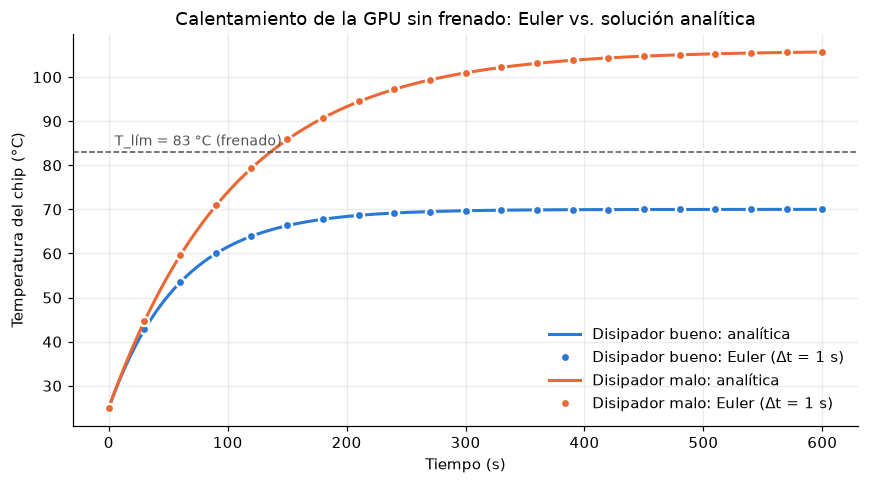

In [3]:
dt = 1.0          # s
t_final = 600.0   # s (10 minutos)
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
for R, color, nombre in [(R_BUENO, AZUL, "Disipador bueno"), (R_MALO, NARANJA, "Disipador malo")]:
    t, T = euler(F_sin_frenado(R), T_AMB, dt, t_final)
    ax.plot(t_fino, T_analitica(t_fino, R), color=color, lw=2, label=f"{nombre}: analítica")
    ax.plot(t[::30], T[::30], "o", color=color, ms=6, mec="white", mew=1.5,
            label=f"{nombre}: Euler (Δt = {dt:g} s)")
    err = np.max(np.abs(T - T_analitica(t, R)))
    print(f"{nombre}: error máximo de Euler = {err:.3f} °C")

ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
ax.text(5, T_LIM + 1.5, f"T_lím = {T_LIM:g} °C (frenado)", color=GRIS, fontsize=9)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title("Calentamiento de la GPU sin frenado: Euler vs. solución analítica")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figuras/validacion_analitica.png", dpi=200)
plt.show()

**Interpretación.** Euler sigue la solución analítica con un error máximo menor a medio grado. Las dos curvas tienen la forma de la carga de un condensador: suben rápido al principio y se aplanan cerca de $T_{amb} + P R_{th}$. El disipador malo no solo llega más alto, también tarda más en estabilizarse porque su $\tau$ es mayor. Además, cruza la línea de 83 °C a los pocos minutos: en la realidad, en ese momento el chip empezaría a frenar, que es lo que modela la Fase 2.

## 6. Validación 2: ¿cómo cambia el error con $\Delta t$?

Si Euler es de primer orden, al dividir $\Delta t$ entre 10 el error también debe dividirse aproximadamente entre 10. En una gráfica log-log eso es una recta de **pendiente 1**.

Pendiente del ajuste log-log: 1.029  (se espera ≈ 1 para Euler)


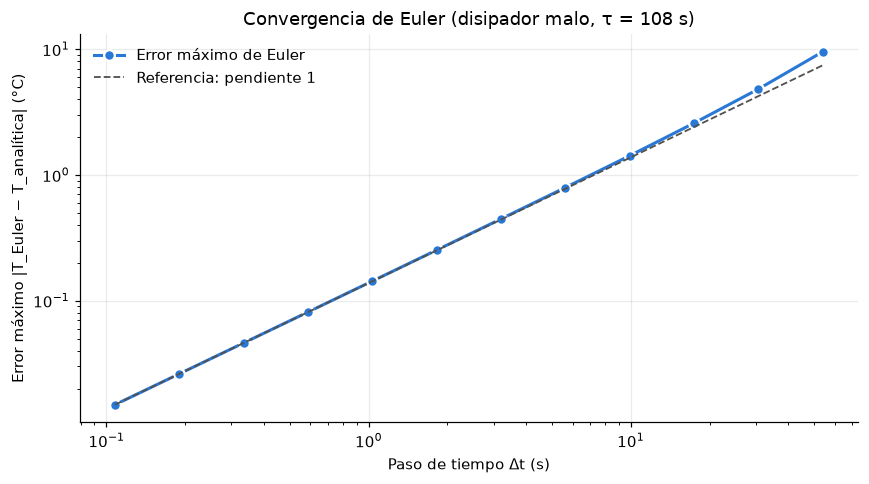

In [4]:
R = R_MALO
tau = R * C_TH
t_final = 5 * tau
pasos = tau * np.logspace(-3, np.log10(0.5), 12)   # desde tau/1000 hasta tau/2

errores = []
for h in pasos:
    t, T = euler(F_sin_frenado(R), T_AMB, h, t_final)
    errores.append(np.max(np.abs(T - T_analitica(t, R))))
errores = np.array(errores)

pendiente, _ = np.polyfit(np.log10(pasos), np.log10(errores), 1)
print(f"Pendiente del ajuste log-log: {pendiente:.3f}  (se espera ≈ 1 para Euler)")

fig, ax = plt.subplots()
ax.loglog(pasos, errores, "o-", color=AZUL, ms=7, mec="white", mew=1.5, label="Error máximo de Euler")
ax.loglog(pasos, errores[0] * (pasos / pasos[0]), "--", color=GRIS, lw=1.2, label="Referencia: pendiente 1")
ax.set_xlabel("Paso de tiempo Δt (s)")
ax.set_ylabel("Error máximo |T_Euler − T_analítica| (°C)")
ax.set_title(f"Convergencia de Euler (disipador malo, τ = {tau:.0f} s)")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/convergencia_euler.png", dpi=200)
plt.show()

**Interpretación.** La pendiente sale muy cerca de 1, que confirma que nuestra implementación se comporta como un método de primer orden: el error es proporcional a $\Delta t$. En la práctica, esto nos da la regla para elegir el paso: si queremos que el error sea menor a una décima de grado, basta leer en la gráfica qué $\Delta t$ lo garantiza.

## 7. Estabilidad de Euler: ¿qué pasa si el paso es muy grande?

Llamemos $u = T - T_{eq}$ a la distancia al equilibrio. Al sustituir en Euler, cada paso multiplica esa distancia por un factor fijo:

$$
u_{k+1} = \left(1 - \frac{\Delta t}{\tau}\right) u_k .
$$

- Si $0 < \Delta t < \tau$: el factor está entre 0 y 1, y la solución se acerca al equilibrio sin oscilar (correcto).
- Si $\tau < \Delta t < 2\tau$: el factor es negativo, y la solución **oscila** alrededor del equilibrio aunque la física real no oscila.
- Si $\Delta t > 2\tau$: el factor tiene valor absoluto mayor que 1, y la solución **diverge**.

Este es exactamente el tipo de pregunta de la sustentación: "¿qué pasa si duplican el paso de tiempo?".

Δt = 0.5τ -> factor por paso 1 - Δt/τ = +0.50
Δt = 1.5τ -> factor por paso 1 - Δt/τ = -0.50
Δt = 2.2τ -> factor por paso 1 - Δt/τ = -1.20


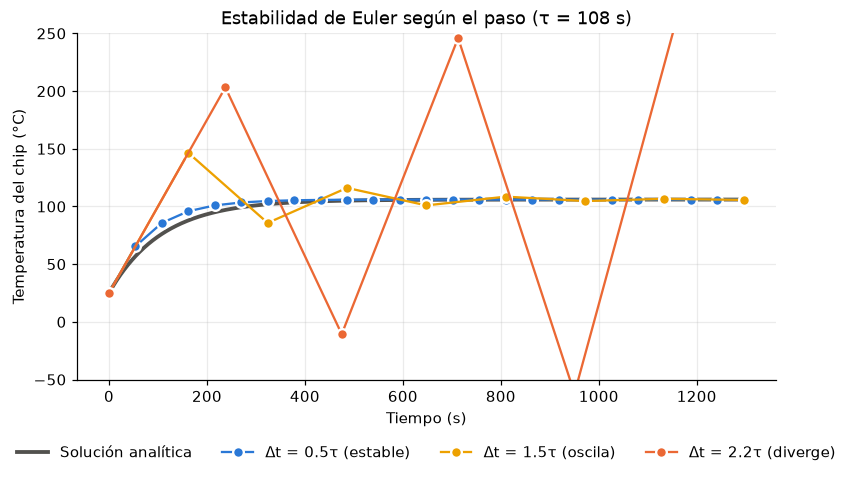

In [5]:
R = R_MALO
tau = R * C_TH
t_final = 12 * tau
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
ax.plot(t_fino, T_analitica(t_fino, R), color=GRIS, lw=2.5, label="Solución analítica")
casos = [(0.5, AZUL, "estable"), (1.5, AMARILLO, "oscila"), (2.2, NARANJA, "diverge")]
for factor, color, nombre in casos:
    t, T = euler(F_sin_frenado(R), T_AMB, factor * tau, t_final)
    ax.plot(t, T, "o-", color=color, ms=7, lw=1.5, mec="white", mew=1.5,
            label=f"Δt = {factor:g}τ ({nombre})")
    print(f"Δt = {factor:g}τ -> factor por paso 1 - Δt/τ = {1 - factor:+.2f}")

ax.set_ylim(-50, 250)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title(f"Estabilidad de Euler según el paso (τ = {tau:.0f} s)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
fig.tight_layout()
fig.savefig("figuras/estabilidad_euler.png", dpi=200)
plt.show()

**Interpretación.** Con $\Delta t = 0.5\tau$ la simulación es tosca pero correcta. Con $\Delta t = 1.5\tau$ aparecen oscilaciones que no son físicas: el chip no "rebota" de temperatura en la realidad, es un artefacto del método. Con $\Delta t = 2.2\tau$ la temperatura crece sin límite. Conclusión práctica: en todas las simulaciones usaremos $\Delta t \ll \tau$. Esto será todavía más importante con el frenado, porque la regla de control también puede producir oscilaciones numéricas.

---
## 8. Frenado térmico *(Fase 2 — en construcción)*

- Agregar la frecuencia $f(t)$ como variable de estado y la regla de frenado.
- Comparar un control de encendido/apagado con uno proporcional.
- Graficar $T(t)$ y $f(t)$ para el disipador bueno y el malo.

## 9. Acoplamiento con el ataque *(Fase 2 — en construcción)*

- Integrar los intentos acumulados $\int r(f(t))\,dt$ hasta cubrir $95^N$ combinaciones.
- Acumular la energía eléctrica y la de refrigeración, $W = Q/\mathrm{COP}$.

## 10. Medición propia *(Fase 3 — en construcción)*

- Cargar los CSV de `medicion/datos/` generados con `medicion/benchmark.py`.
- Ajustar $\tau$ y comparar con el modelo.

## 11. Barridos de parámetros *(Fase 4 — en construcción)*

- Longitud $N$, tipo de hash (NTLM vs. bcrypt), $R_{th}$ y $T_{amb}$; costo en kWh y en pesos.

## 12. Límite de Landauer *(Fase 4 — en construcción)*

## 13. Demo interactiva *(Fase 6 — en construcción)*

## 14. Limitaciones

## 15. Conclusiones

## 16. Declaración de uso de IA *(obligatoria)*